# Graphiques

### Comparaison reward DAgger vs RLPD

<>:25: SyntaxWarning: invalid escape sequence '\p'
<>:25: SyntaxWarning: invalid escape sequence '\p'
/var/folders/1n/y44nm8wn4d7_c007zc7xn_hh0000gn/T/ipykernel_82724/2323474987.py:25: SyntaxWarning: invalid escape sequence '\p'
  plt.title("Récompense moyenne $\pm$ écart-type sur 3 seeds")


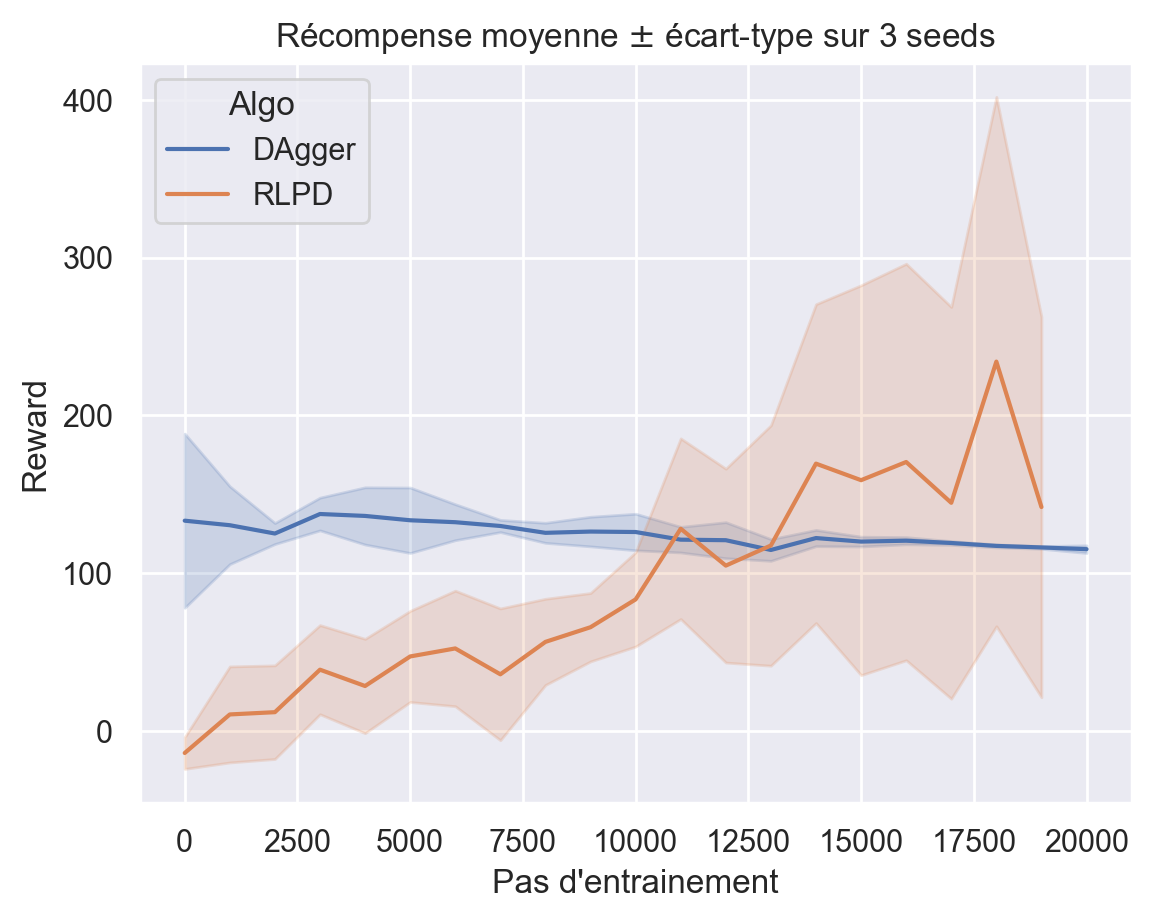

In [9]:
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

dfs = []
for algo, prefix in [("DAgger","metrics_dagger"),("RLPD","metrics_rlpd")]:
    for seed in range(3):
        d = np.load(f"logs/{prefix}_{seed}.npz")
        steps = (np.cumsum(d["lengths"])//1000)*1000
        dfs.append(pd.DataFrame({
            "Pas d'entrainement":steps,
            "Reward":pd.Series(d["rewards"]).expanding().mean(),
            "Pas par épisode":pd.Series(d["lengths"]).expanding().mean(),
            "Algo":algo,
            "Seed":seed
        }))


data = pd.concat(dfs, ignore_index=True)
sn.set_theme(style="darkgrid")

sn.lineplot(data=data, x="Pas d'entrainement", y="Reward", hue="Algo",errorbar="sd")
plt.title("Récompense moyenne $\pm$ écart-type sur 3 seeds")
plt.show()


### Comparaison Pas Par episode

<>:2: SyntaxWarning: invalid escape sequence '\p'
<>:2: SyntaxWarning: invalid escape sequence '\p'
/var/folders/1n/y44nm8wn4d7_c007zc7xn_hh0000gn/T/ipykernel_82724/119053859.py:2: SyntaxWarning: invalid escape sequence '\p'
  plt.title("Évolution du pas de tour  $\pm$ écart type sur 3 seeds")


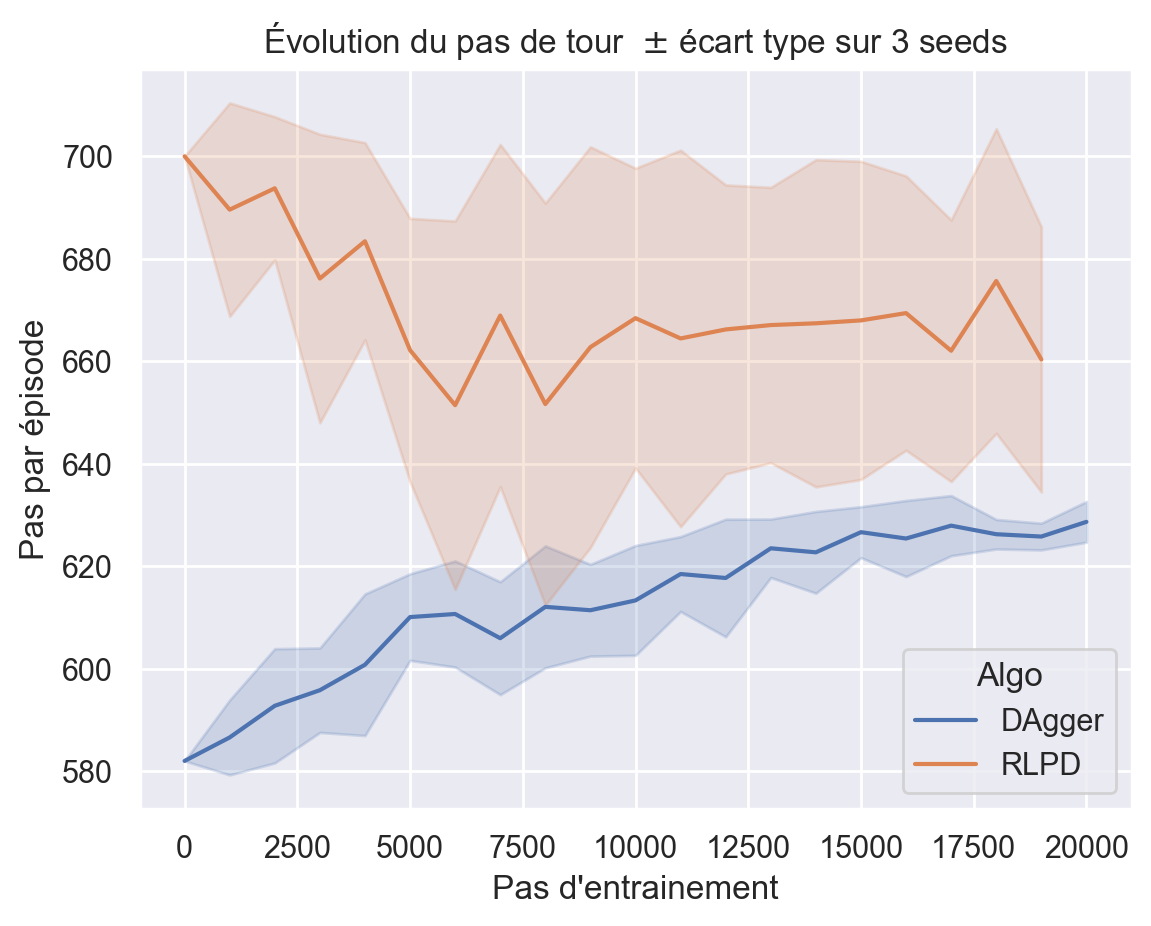

In [12]:
sn.lineplot(data=data, x="Pas d'entrainement", y="Pas par épisode", hue="Algo",errorbar="sd")
plt.title("Évolution du pas de tour  $\pm$ écart type sur 3 seeds")
plt.show()
